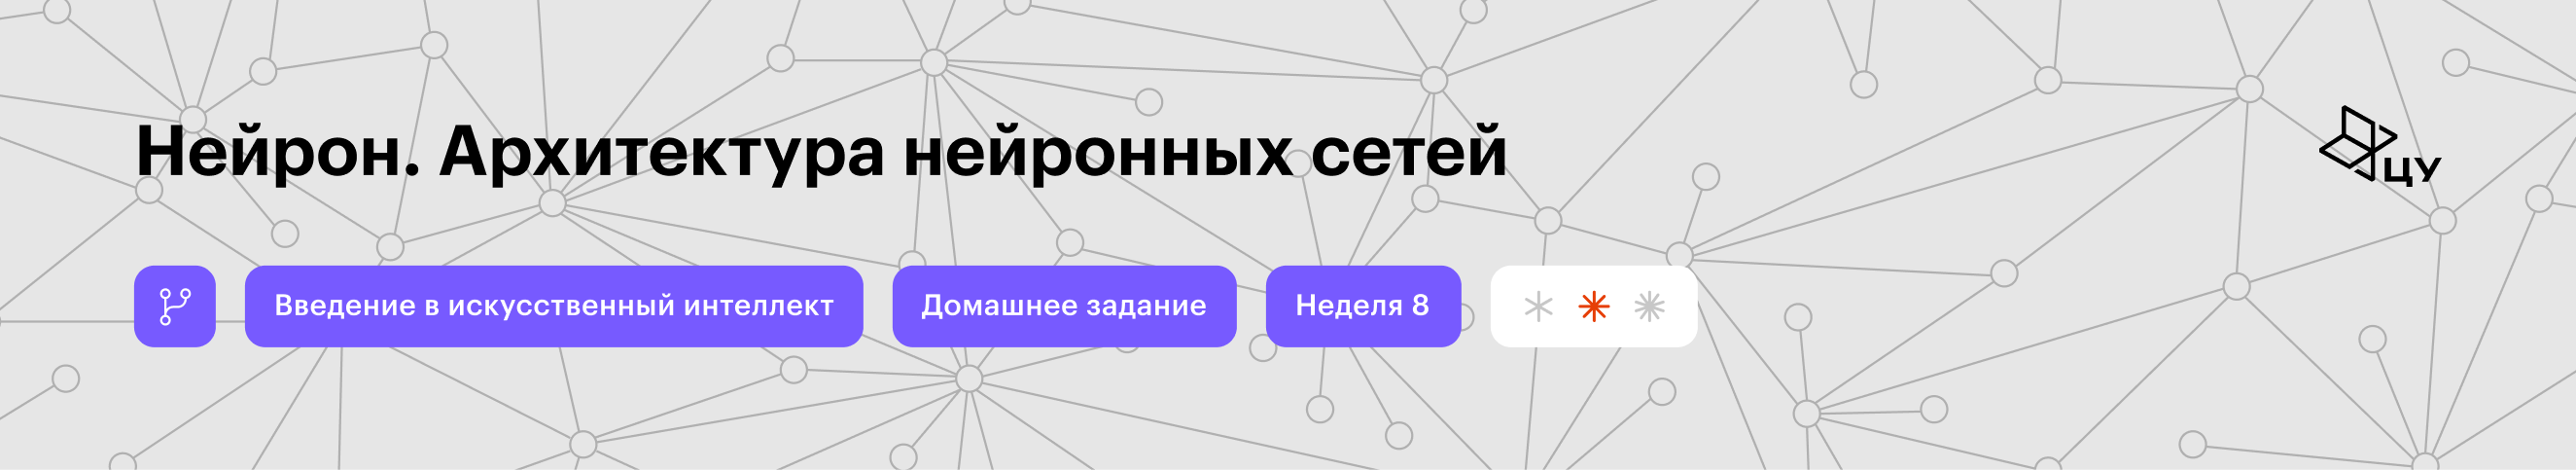

# Домашнее задание по теме «Нейрон. Архитектура нейронных сетей»

В этом домашнем задании ты продолжишь экспериментировать с простыми полносвязными нейросетями и увидишь, как на качество решения влияют:
*   нормализация,
*   функции активации,
*   ширина и глубина скрытых слоёв.

>### Правила домашнего задания
>1. Нельзя удалять существующие ячейки кода.
>
>2. Можно добавлять и дописывать свои ячейки.
>
>3. Место, куда тебе нужно написать код, помечается комментарием.
>
> 4. Ответ без кода, который подтвердит твоё решение, не засчитывается. Исключение — задачи и вопросы, где код не требуется и нужно сделать вывод из известных данных.
>
 > 5. Код должен быть работоспособным. У проверяющих должна быть возможность воспроизвести все полученные результаты.

## Установка библиотек

In [2]:
import random
import subprocess

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn


In [2]:
# Эта ячейка поможет сделать эксперименты воспроизводимыми
SEED = 264

# Python/NumPy
random.seed(SEED)
np.random.seed(SEED)

# PyTorch (CPU + GPU)
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Воспроизводимость
torch.use_deterministic_algorithms(True)

In [7]:
# Загружаем данные в среду
subprocess.run(["gdown", "1EzwSMPRec96B0pte-r3qgiZlFp4igAEy"], check=False)

Using cookies from /home/igor/.cache/gdown/cookies.txt
Downloading...
From: https://drive.google.com/uc?id=1EzwSMPRec96B0pte-r3qgiZlFp4igAEy
To: /home/igor/dev/competitive-py/ai/dataset_zigzag_gap1.csv
100%|██████████| 30.0k/30.0k [00:00<00:00, 67.5MB/s]


CompletedProcess(args=['gdown', '1EzwSMPRec96B0pte-r3qgiZlFp4igAEy'], returncode=0)

In [9]:
# Загружаем данные в среду
subprocess.run(["gdown", "1YK8inP21BSKuGK2V85C9VgYpDwDLzSOT"], check=False)

Using cookies from /home/igor/.cache/gdown/cookies.txt
Downloading...
From: https://drive.google.com/uc?id=1YK8inP21BSKuGK2V85C9VgYpDwDLzSOT
To: /home/igor/dev/competitive-py/ai/dataset_small_points.csv
100%|██████████| 338/338 [00:00<00:00, 942kB/s]


CompletedProcess(args=['gdown', '1YK8inP21BSKuGK2V85C9VgYpDwDLzSOT'], returncode=0)

In [8]:
# Загружаем данные в среду
subprocess.run(["gdown", "1Nt1v-oIBVzVLGPCm6hgEZ_GHOzQZG4z6"], check=False)

Using cookies from /home/igor/.cache/gdown/cookies.txt
Downloading...
From: https://drive.google.com/uc?id=1Nt1v-oIBVzVLGPCm6hgEZ_GHOzQZG4z6
To: /home/igor/dev/competitive-py/ai/dataset_four_rings.csv
100%|██████████| 20.1k/20.1k [00:00<00:00, 26.6MB/s]


CompletedProcess(args=['gdown', '1Nt1v-oIBVzVLGPCm6hgEZ_GHOzQZG4z6'], returncode=0)

## Датасеты

1) `dataset_small_points.csv` — датасет с семинара.
2) `dataset_four_rings.csv` — четыре концентрических окружности.
3) `dataset_zigzag_gap1.csv` — зигзагообразная граница с зазором.

Формат: CSV с колонками `x1`, `x2` и `y`, где $y \in \{0, 1\}$.



## Вспомогательные функции

Какие-то из этих функций уже знакомы тебе по семинарам, а какие-то ты увидишь впервые. Вспомогательные функции упрощают дизайн экспериментов, поэтому у тебя останется больше сил на размышление, исследование и сами эксперименты.

Так как аналитикам данных часто приходится разбираться в чужом коде, мы намеренно не добавляли описание к функциям.

In [6]:
def load_csv_dataset(path: str):
    df = pd.read_csv(path)
    X = df[["x1", "x2"]].values.astype(np.float32)
    y = df[["y"]].values.astype(np.float32)
    return X, y


def quick_scatter(X, y, title=None):
    x_blue = X[y[:, 0] == 1, 0]
    y_blue = X[y[:, 0] == 1, 1]
    x_orange = X[y[:, 0] == 0, 0]
    y_orange = X[y[:, 0] == 0, 1]

    plt.figure(figsize=(6.8, 5.2))
    plt.scatter(x_blue, y_blue, s=80, c="tab:blue", label="Класс 1")
    plt.scatter(x_orange, y_orange, s=80, c="tab:orange", label="Класс 0")

    plt.grid(alpha=0.3)
    if title:
        plt.title(title)
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.legend()
    plt.show()


@torch.no_grad()
def plot_data_and_boundary(
    model,
    X_train_np,
    y_train_np,
    X_mean,
    X_std,
    grid_n=200,
    pad=0.8,
    title="Данные и граница решения",
):
    model.eval()

    x_blue = X_train_np[y_train_np[:, 0] == 1, 0]
    y_blue = X_train_np[y_train_np[:, 0] == 1, 1]
    x_orange = X_train_np[y_train_np[:, 0] == 0, 0]
    y_orange = X_train_np[y_train_np[:, 0] == 0, 1]

    x_min, x_max = (
        float(X_train_np[:, 0].min() - pad),
        float(X_train_np[:, 0].max() + pad),
    )
    y_min, y_max = (
        float(X_train_np[:, 1].min() - pad),
        float(X_train_np[:, 1].max() + pad),
    )

    xs = np.linspace(x_min, x_max, grid_n, dtype=np.float32)
    ys = np.linspace(y_min, y_max, grid_n, dtype=np.float32)
    Xg, Yg = np.meshgrid(xs, ys)
    grid = np.stack([Xg.ravel(), Yg.ravel()], axis=1)
    grid_t = torch.tensor(grid)

    grid_tn = (grid_t - X_mean) / X_std

    logits = model(grid_tn).reshape(-1)
    probs = torch.sigmoid(logits).reshape(grid_n, grid_n).cpu().numpy()

    _fig, ax = plt.subplots(figsize=(9.5, 6.5))
    cf = ax.contourf(Xg, Yg, probs, levels=30, alpha=0.35)
    plt.colorbar(cf, ax=ax, label="P(class=1)")

    ax.contour(Xg, Yg, probs, levels=[0.5], linewidths=2)

    ax.scatter(x_blue, y_blue, s=70, c="tab:blue", label="Класс 1")
    ax.scatter(x_orange, y_orange, s=70, c="tab:orange", label="Класс 0")

    ax.grid(True, alpha=0.3)
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()

In [7]:
@torch.no_grad()
def compute_metrics(model, Xn, y, criterion):
    model.eval()
    logits = model(Xn)  # (N,1)
    loss = criterion(logits, y).item()
    preds = (logits >= 0).float()  # Логит 0 соответствует вероятности 0,5
    acc = (preds.eq(y)).float().mean().item()
    return loss, acc


def make_train_step(model, Xn, y, criterion, optimizer):
    def train_step():
        model.train()
        optimizer.zero_grad()
        logits = model(Xn)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        return compute_metrics(model, Xn, y, criterion)

    return train_step

In [8]:
def print_model_summary_and_weights(model):
    print("=== Архитектура модели ===")
    print(model)

    print("\n=== Параметры (веса и смещения) ===")
    for name, module in model.named_modules():
        if isinstance(module, nn.Linear):
            W = module.weight.detach().cpu().numpy()
            b = module.bias.detach().cpu().numpy()
            print(
                f"\n[{name}] Linear(in={module.in_features}, out={module.out_features})"
            )
            print("W =")
            print(np.array2string(W, precision=4, suppress_small=True))
            print("b =")
            print(np.array2string(b, precision=4, suppress_small=True))

In [9]:
def print_history(history):
    losses = [l for l, _ in history]
    accs = [a for _, a in history]

    _fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    ax1.plot(losses)
    ax1.set_xlabel("Эпоха")
    ax1.set_ylabel("Loss (BCE)")
    ax1.set_title("Функция потерь")
    ax1.grid(alpha=0.3)

    ax2.plot(accs)
    ax2.axhline(0.515, color="gray", linestyle="--", label="baseline (доля класса 1)")
    ax2.set_xlabel("Эпоха")
    ax2.set_ylabel("Accuracy")
    ax2.set_title("Точность")
    ax2.legend()
    ax2.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()

    print(f"Итог: loss = {losses[-1]:.4f}, accuracy = {accs[-1]:.3f}")

In [10]:
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    # torch.use_deterministic_algorithms(True) на GPU требует настройки cuBLAS
    os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
print("device:", device)


def make_model(act, h=8, depth=2, device=device):
    torch.manual_seed(SEED)
    layers, d_in = [], 2
    for _ in range(depth):
        layers += [nn.Linear(d_in, h), act()]
        d_in = h
    layers.append(nn.Linear(d_in, 1))
    return nn.Sequential(*layers).to(device)


def run_experiment(
    model,
    X_np,
    y_np,
    normalize=True,
    epochs=2000,
    lr=0.01,
    title="",
    plot=True,
    do_print_history=True,
):
    dev = next(model.parameters()).device  # учимся там же, где лежит модель

    X_t = torch.tensor(X_np)
    y_t = torch.tensor(y_np)

    if normalize:
        X_mean, X_std = X_t.mean(dim=0), X_t.std(dim=0)
    else:
        X_mean, X_std = torch.zeros(2), torch.ones(2)
    Xn_t = ((X_t - X_mean) / X_std).to(dev)
    y_t = y_t.to(dev)

    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    train_step = make_train_step(model, Xn_t, y_t, nn.BCEWithLogitsLoss(), optimizer)

    history = [train_step() for _ in range(epochs)]

    if plot:
        # plot_data_and_boundary строит сетку на CPU, поэтому временно переносим модель туда
        plot_data_and_boundary(model.cpu(), X_np, y_np, X_mean, X_std, title=title)
        model.to(dev)
    if do_print_history:
        print_history(history)
    return history

device: cuda


---

## Задание 1 [0,5 балла]


1.   Напиши код, считывающий данные из датасетов — **[0,25 балла]**.
2.   Выведи данные при помощи функции `quick_scatter` — **[0,25 балла]**.


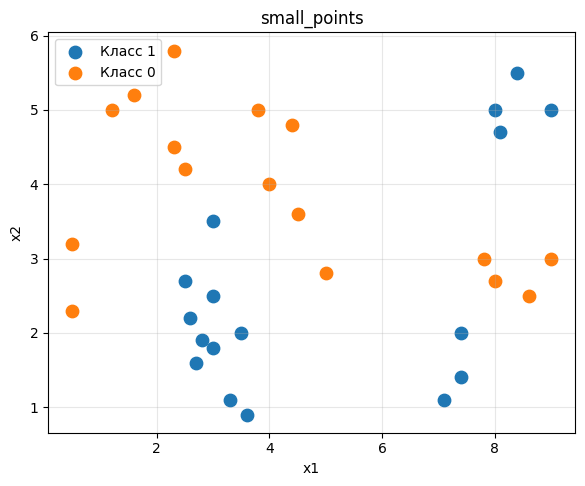

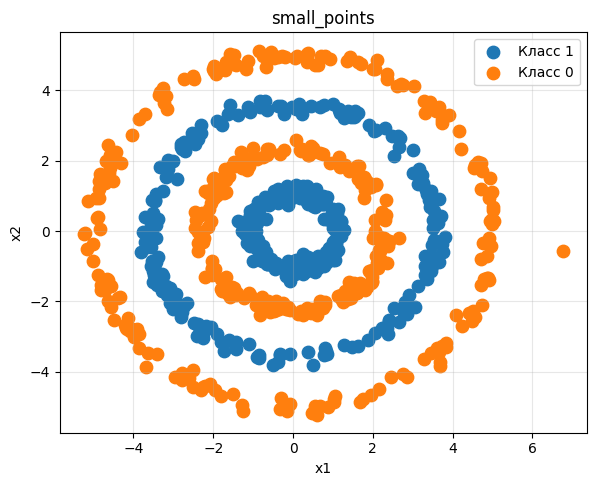

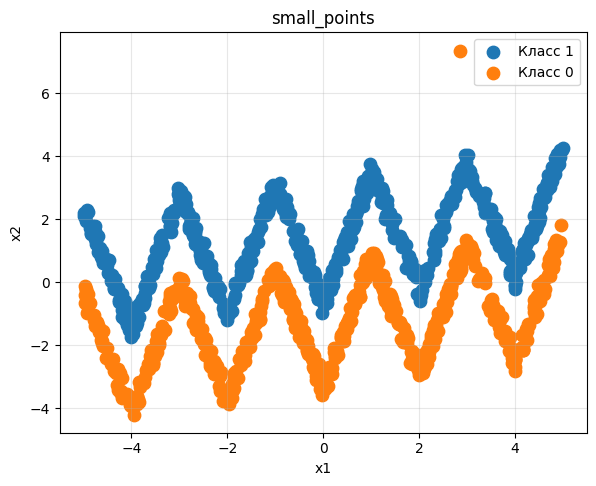

In [11]:
# Напиши код здесь
small_pointsX, small_pointsY = load_csv_dataset("dataset_small_points.csv")
four_ringsX, four_ringsY = load_csv_dataset("dataset_four_rings.csv")
zigzag_gap1X, zigzag_gap1Y = load_csv_dataset("dataset_zigzag_gap1.csv")

quick_scatter(small_pointsX, small_pointsY, "small_points")
quick_scatter(four_ringsX, four_ringsY, "small_points")
quick_scatter(zigzag_gap1X, zigzag_gap1Y, "small_points")

---

## Задание 2 [1,5 балла]

На семинаре мы работали с простыми нейронными сетями и пытались интерпретировать их поведение. Продолжим эксперименты.

1) Создай нейросеть с **двумя скрытыми слоями** и функцией активации $\tanh(5x)$, как на семинаре    — **[0,5 балла]**.
2) Обучи нейросеть на **ненормализованных** данных (лучше взять `BCEWithLogitsLoss()` в качестве функционала ошибки) и выведи поле вероятностей при помощи функции `plot_data_and_boundary`. Вспомогательные функции ждут, что сеть возвращает логиты, поэтому сигмоиду на выходе ставить не нужно — **[0,5 балла]**.
3) Оцени, насколько качественно обучилась нейросеть — **[0,1 балла]**.
4) Выдвини две гипотезы, почему так могло произойти — **[0,4 балла]**.

**Датасет:** `dataset_small_points.csv`.

In [12]:
# Напиши код здесь
class Tanh5x(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return torch.tanh(5 * x)

In [13]:
Tanh5x()(torch.tensor([0.0, 0.1, 1.0]))  # проверка что простенький модуль работает

tensor([0.0000, 0.4621, 0.9999])

In [14]:
print("baseline", small_pointsY.mean())

baseline 0.5151515


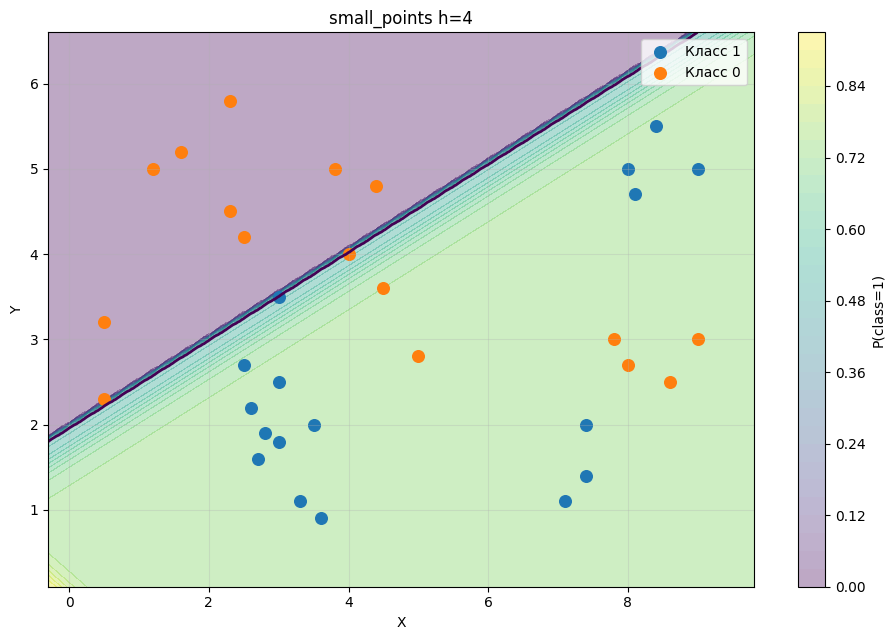

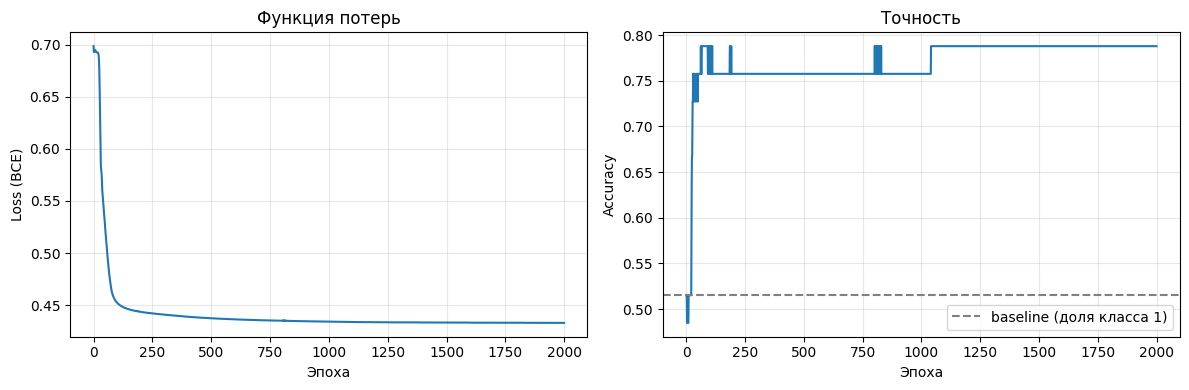

Итог: loss = 0.4331, accuracy = 0.788


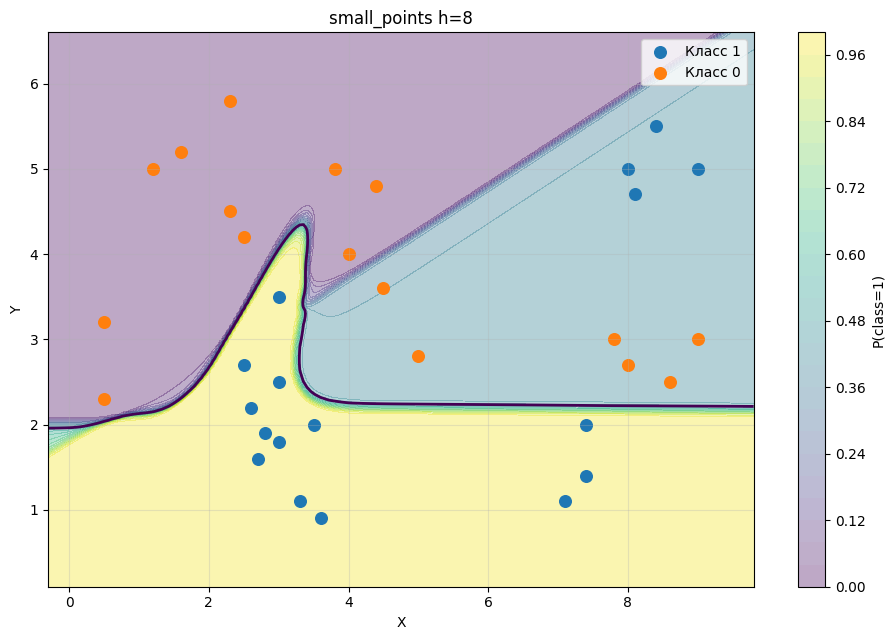

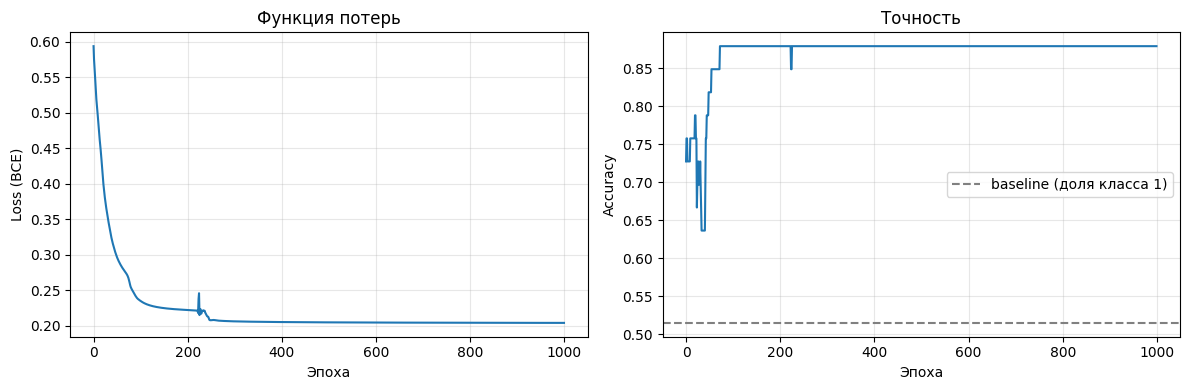

Итог: loss = 0.2043, accuracy = 0.879


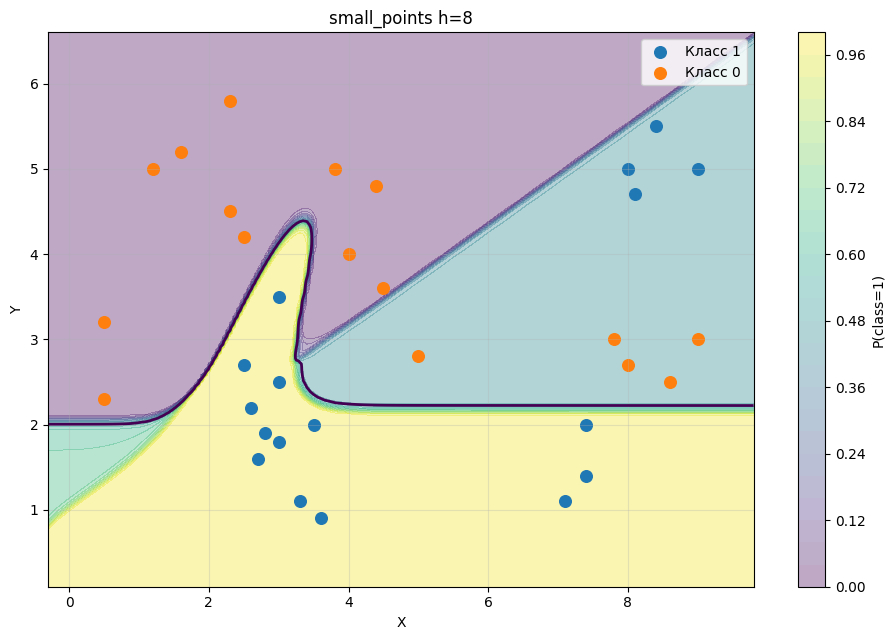

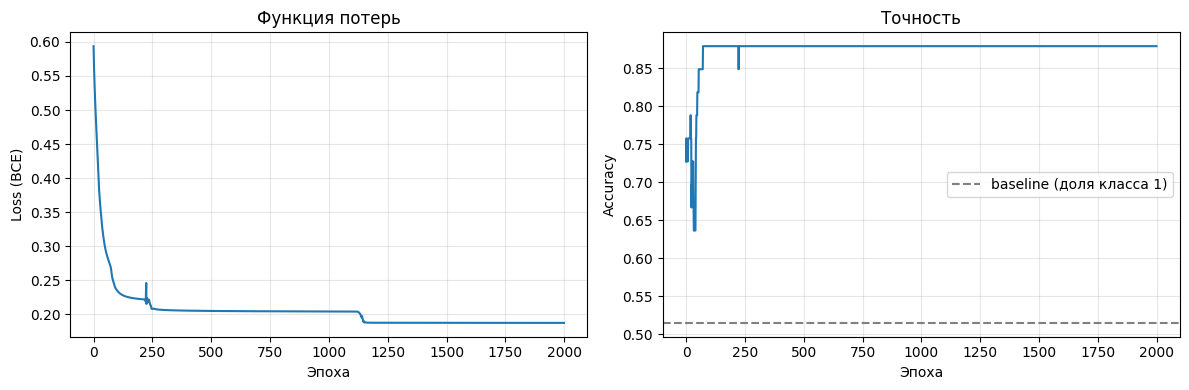

Итог: loss = 0.1875, accuracy = 0.879


In [15]:
torch.manual_seed(SEED)
_ = run_experiment(
    make_model(Tanh5x, h=4),
    small_pointsX,
    small_pointsY,
    normalize=False,
    title="small_points h=4",
)
_ = run_experiment(
    make_model(Tanh5x, h=8),
    small_pointsX,
    small_pointsY,
    normalize=False,
    epochs=1000,
    title="small_points h=8",
)
_ = run_experiment(
    make_model(Tanh5x, h=8),
    small_pointsX,
    small_pointsY,
    normalize=False,
    title="small_points h=8",
)

~~сеть выучила больше, чем бейзлайн (0.5151515 < 0.788)~~
я вынес эксперимент в отдельную функцию и перепрогнал на h=8, а не h=4 как до этого и получил гораздо более умную систему, которая выдает 0.879

~~я вижу, что сеть выучила прямую, хотя данные более хаотичные, плюс переход от синей области к фиолетовой мгновенный, почти ступенька~~ сеть выучила достаточно сложную структуру, но переходы между зонами 0 - 1 - 0.66 максимально жесткие

~~loss вышел на плато примерно к 150 эпохе, достигнув локального минимума~~ на 250 эпохе достигли первого плато, из которого на 1100 эпохе вышли и дообучились. Выше видно как это плато выглядело: сеть захватила одну точку нулевого класса в фиолетовую зону

## Задание 3 [2 балла]

Проблема обучения может быть связана с неправильно подобранной функцией активации. Чтобы выяснить, так ли это, выполни задания.
1. Обучи нейросеть с функциями активации $\tanh$, $\mathrm{SiLU}$ и $\mathrm{ReLU}$. Укажи, помогает ли какая-то из них лучше решать задачу с ненормализованными данными?  **[0,5 балла]**.
2. Поэкспериментируй с функциями активации вида $\tanh(kx)$. Укажи, зависит ли качество обучения от параметра $k$? **[0,5 балла]**.
3. Поэкспериментируй с функциями активации вида $\mathrm{ReLU}(kx)$. Укажи, зависит ли качество обучения от параметра $k$? **[0,5 балла]**.
4. Выдвинь гипотезу, почему одни функции активации хорошо работают с ненормализованными данными, а другие нет. **[0,5 балла]**.

> Функция SiLU задаётся формулой $\mathrm{SiLU}(x) = x\,\sigma(x)$, где $\sigma$ — сигмоида. При больших положительных $x$ она ведёт себя как ReLU и почти равна $x$, а при больших отрицательных стремится к нулю. Излома в нуле, как у ReLU, у неё нет. В PyTorch это `nn.SiLU()`.



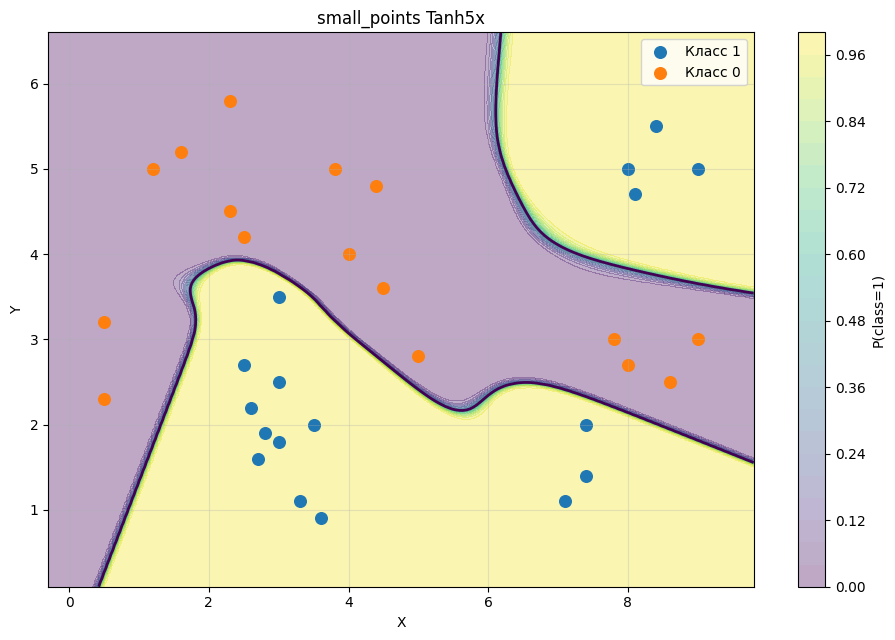

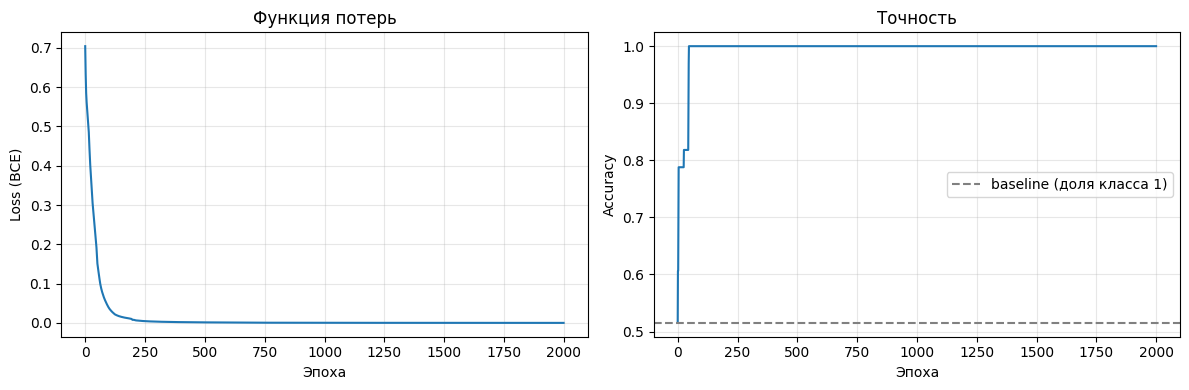

Итог: loss = 0.0001, accuracy = 1.000


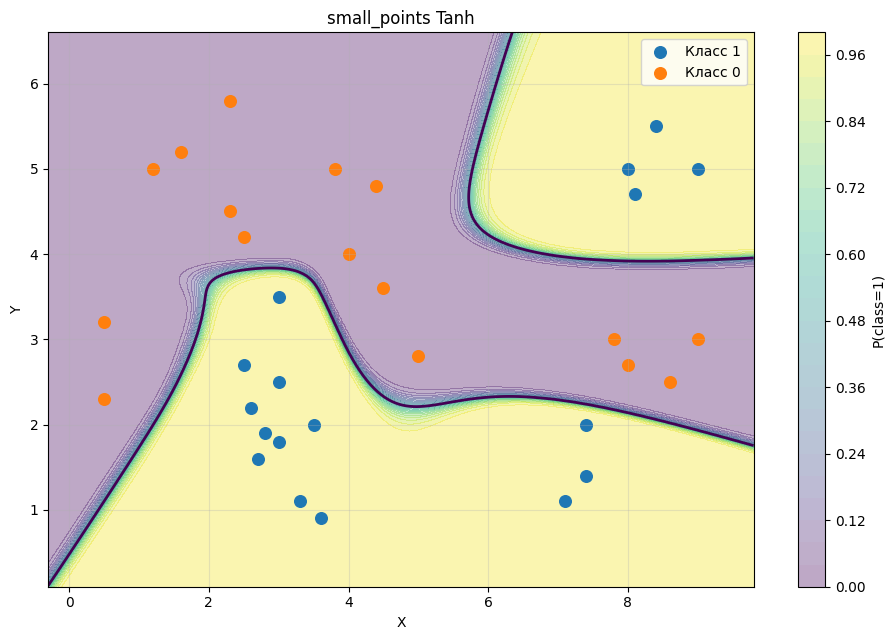

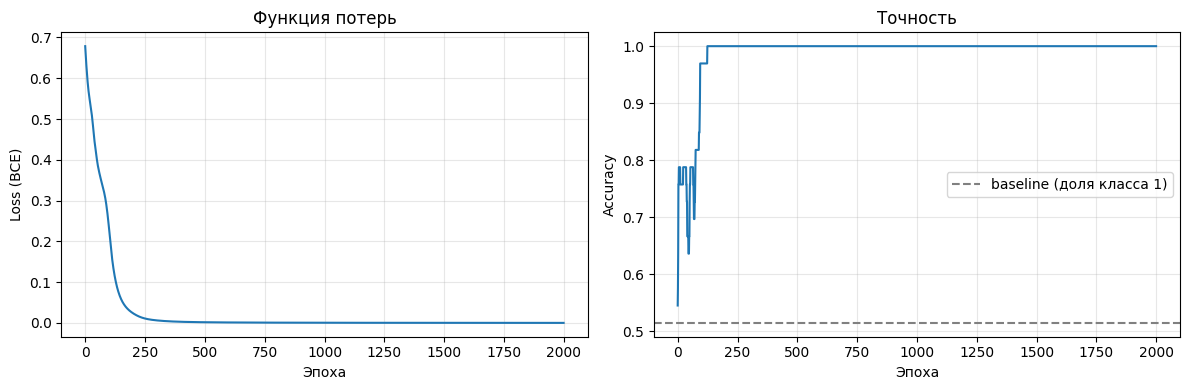

Итог: loss = 0.0001, accuracy = 1.000


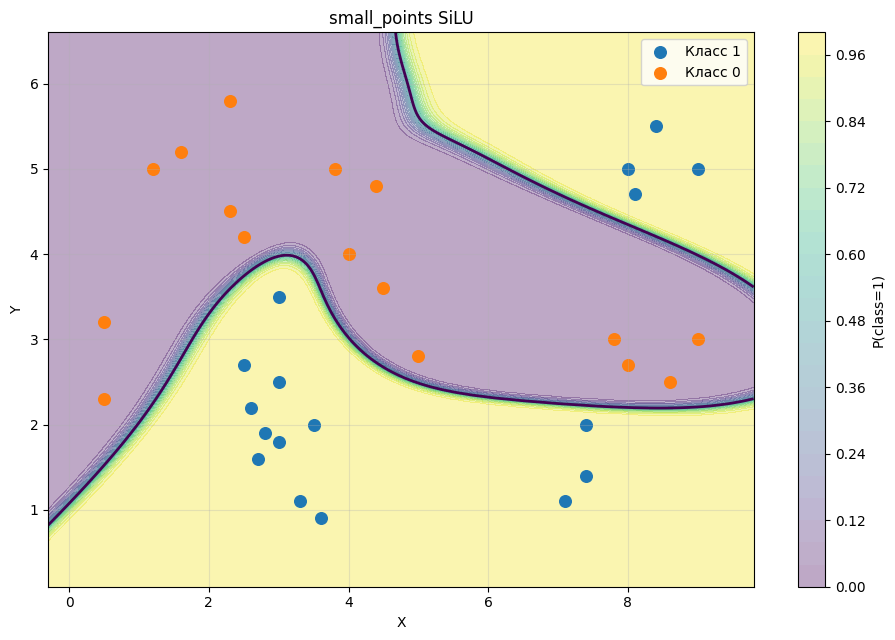

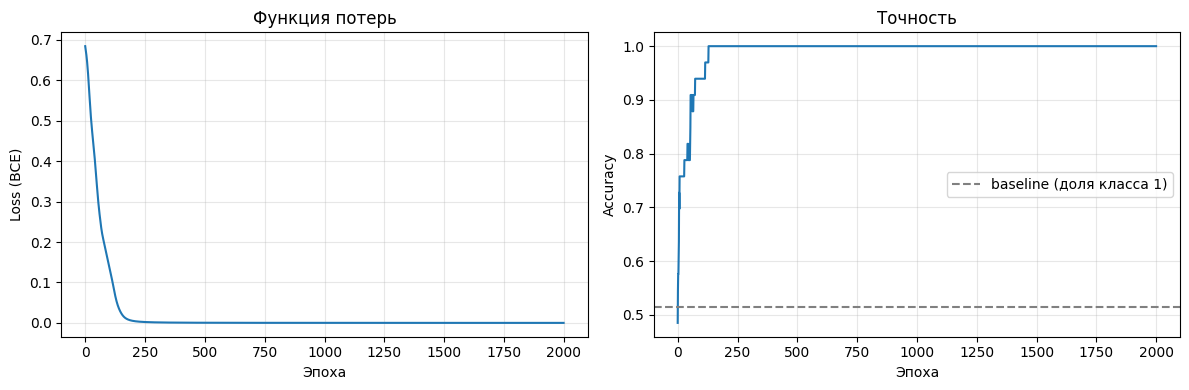

Итог: loss = 0.0000, accuracy = 1.000


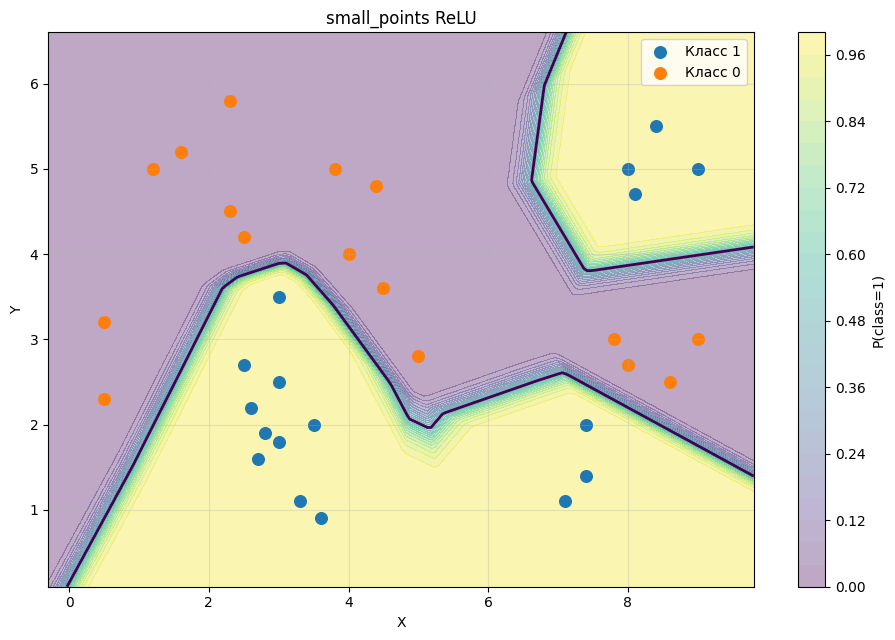

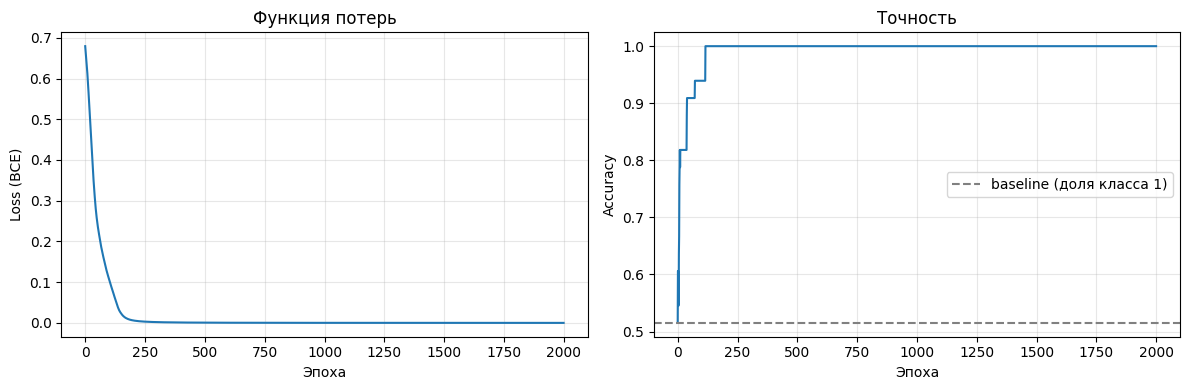

Итог: loss = 0.0000, accuracy = 1.000


In [16]:
# Напиши код здесь

results = {}

for func in [Tanh5x, nn.Tanh, nn.SiLU, nn.ReLU]:
    history = run_experiment(
        make_model(func, h=8),
        small_pointsX,
        small_pointsY,
        normalize=True,
        title=f"small_points {func.__name__}",
    )
    results[func.__name__] = history[-1]

In [17]:
pd.DataFrame(results, index=["loss", "acc"]).T

,loss,acc
Tanh5x,0.000099,1.0
Tanh,0.000131,1.0
SiLU,0.000017,1.0
ReLU,0.000031,1.0


~~Tanh5x и ReLU превратили нейронную сеть в линейную модель, а Tanh и SiLU очень хорошо научились предсказывать~~
~~Но в тоже время очень маленький loss (< 0.001 на 33 точках) означает, что сети на основе Tanh и SiLU переобучились~~

Видим, что нормализация очень улучшила качество моделей, даже при тех же функциях активации. Подозреваю единственное, что все модели переобучились

## Задание 4 [3 балла]

Теперь возьми датасет `dataset_four_rings.csv`:
-   нормализуй данные и проведи несколько экспериментов;
-   сравни, на что влияют различные параметры в архитектуре нейросетей.




*   **Эксперимент 1**: попробуй разные активации ($\mathrm{ReLU}$, $\mathrm{SiLU}$, $\tanh$) в сети с двумя скрытыми слоями, в каждом из которых не больше 10 нейронов **[1 балл]**.
*   **Эксперимент 2**: выбери функцию активации, поэкспериментируй с количеством нейронов и сравни с экспериментом 1. Хороший вариант — рассмотреть два случая меньше 10 нейронов и два больше 10 **[1 балл]**.
*   **Эксперимент 3**: поэкспериментируй с глубиной нейросети (например 1, 3, 5 слоёв). Ответь, верно ли, что глубокая нейросеть позволит уменьшить число нейронов на первом слое, при этом не потеряв в качестве? Почему? **[1 балл]**


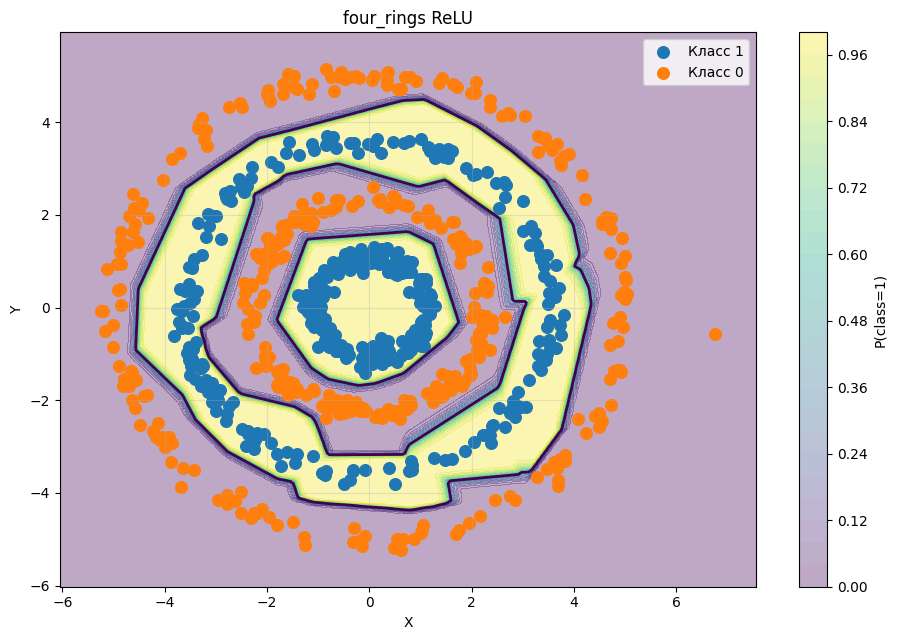

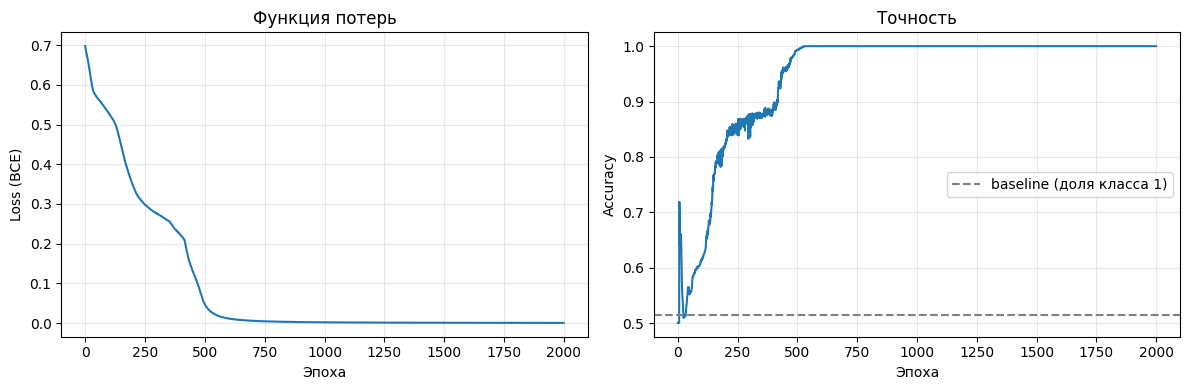

Итог: loss = 0.0003, accuracy = 1.000


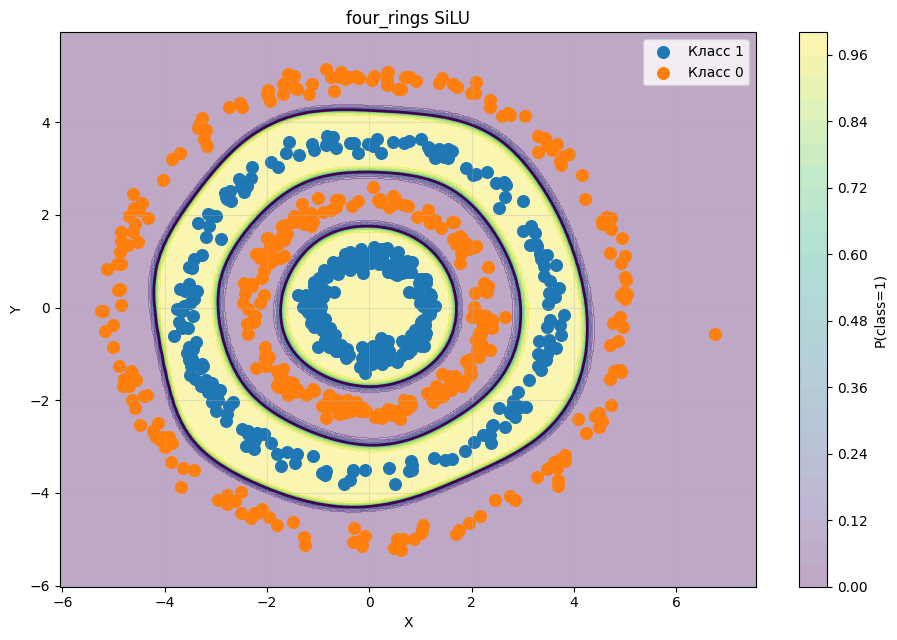

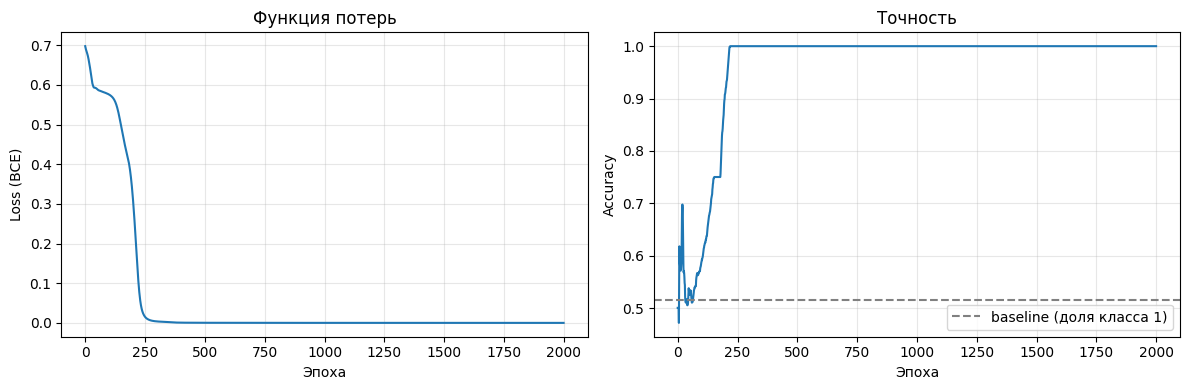

Итог: loss = 0.0000, accuracy = 1.000


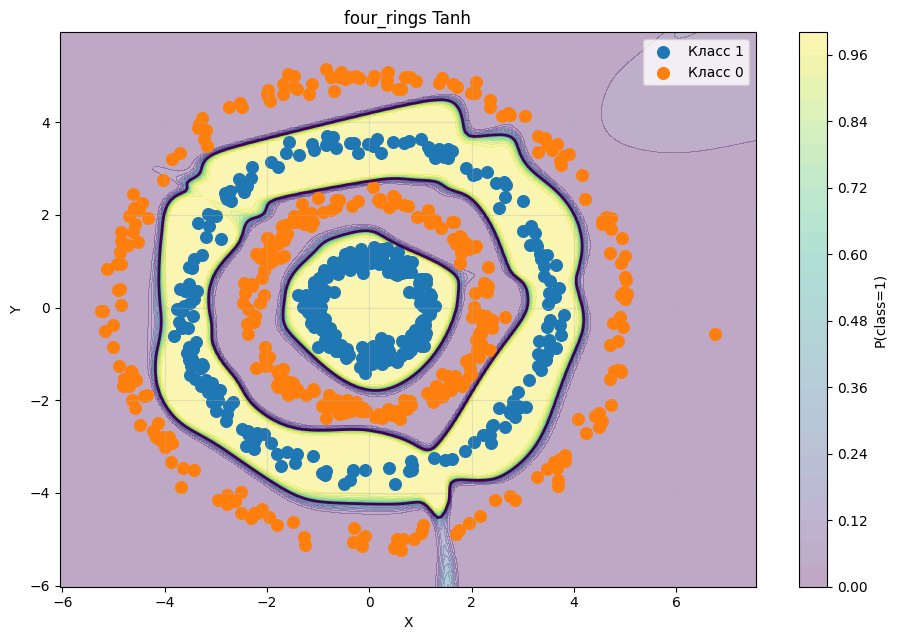

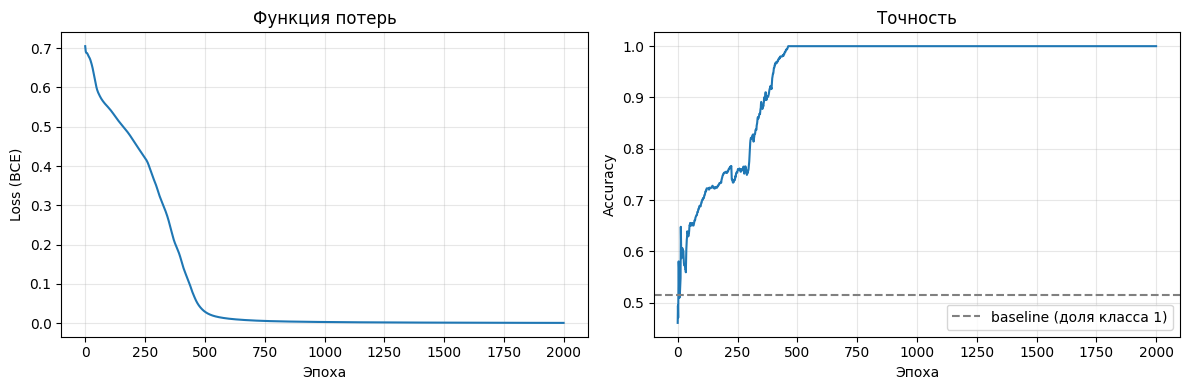

Итог: loss = 0.0008, accuracy = 1.000


In [18]:
# Напиши код здесь
results = {}
for func in [nn.ReLU, nn.SiLU, nn.Tanh]:
    history = run_experiment(
        make_model(func, h=10, depth=2),
        four_ringsX,
        four_ringsY,
        normalize=True,
        title=f"four_rings {func.__name__}",
    )
    results[func.__name__] = history[-1]

In [19]:
pd.DataFrame(results, index=["loss", "acc"]).T

,loss,acc
ReLU,0.000295,1.0
SiLU,0.000019,1.0
Tanh,0.000816,1.0


Чисто визуально мне тут SiLU больше нравится, для эксперимента 2 выбираю ее

In [20]:
results = {}
for h in [4, 8, 10, 14]:
    history = run_experiment(
        make_model(nn.SiLU, h=h, depth=2),
        four_ringsX,
        four_ringsY,
        normalize=True,
        title=f"four_rings h={h}",
        plot=False,
        do_print_history=False,
    )
    results[h] = history[-1]
pd.DataFrame(results, index=["loss", "acc"]).T

,loss,acc
4,0.000422,1.0
8,0.000169,1.0
10,0.000019,1.0
14,0.000008,1.0


я вижу, что чем больше нейронов на уровнях, тем больше качество модели. Когда визуально их строил, модель на 4 нейронах имела жесткие углы, если можно так сказать

In [21]:
results = {}
for depth in [1, 3, 5, 10, 15, 30]:
    history = run_experiment(
        make_model(nn.SiLU, h=16, depth=depth),
        four_ringsX,
        four_ringsY,
        normalize=True,
        title=f"four_rings depth={depth}",
        plot=False,
        do_print_history=False,
    )
    results[depth] = history[-1]
pd.DataFrame(results, index=["loss", "acc"]).T

,loss,acc
1,0.177760,0.973783
3,0.000002,1.000000
5,0.000796,1.000000
10,0.000001,1.000000
15,0.000035,1.000000
30,0.693146,0.500624


In [22]:
print("baseline", four_ringsY.mean())

baseline 0.4993758


Я вижу, что большое количество слоев не гарантирует качество: на 5 слоях модель достигала наилучшего качества, при том что на 30 слоях она угадывала незначительно лучше бейзлайна (0.5 ~ 0.499)

---

## Задание 5 [1,5 балла]

Теперь попробуй провести те же эксперименты на датасете `dataset_zigzag_gap1.csv`.

*   **Эксперимент 1**: попробуй разные активации — $\mathrm{ReLU}$, $\mathrm{SiLU}$, $\tanh$ — в сети с двумя скрытыми слоями, в каждом из которых не больше 10 нейронов **[0,5 балла]**.
*   **Эксперимент 2**: выбери функцию активации, но не ту, что была во втором эксперименте задания 4. Поэкспериментируй с количеством нейронов. Хороший вариант — рассмотреть два случая меньше 10 нейронов и два больше 10. Сравни с экспериментом 1 **[0,5 балла]**.
*   **Эксперимент 3**: поэкспериментируй с глубиной нейросети — например 1, 3, 5 слоёв **[0,5 балла]**.



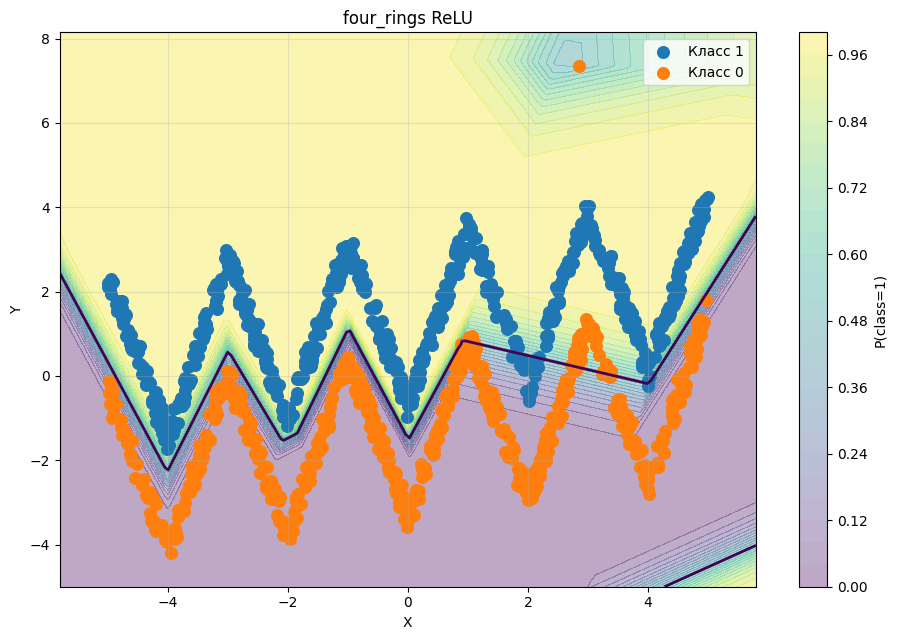

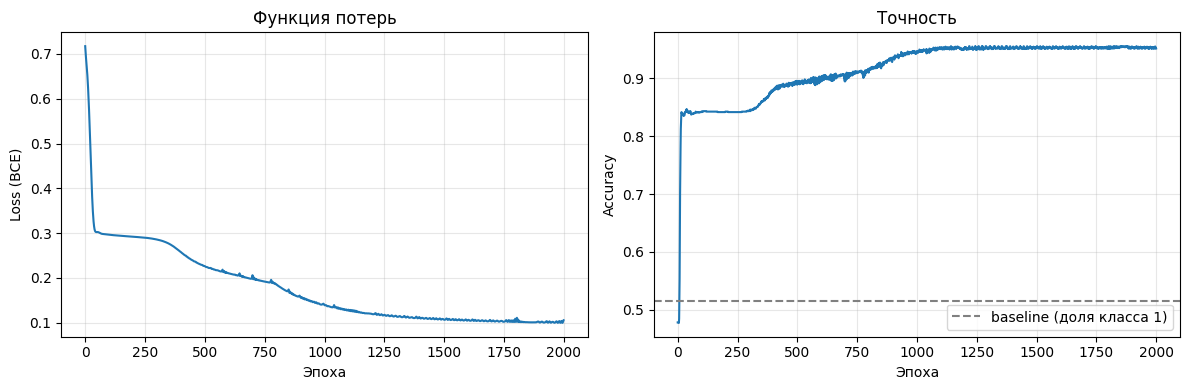

Итог: loss = 0.1055, accuracy = 0.952


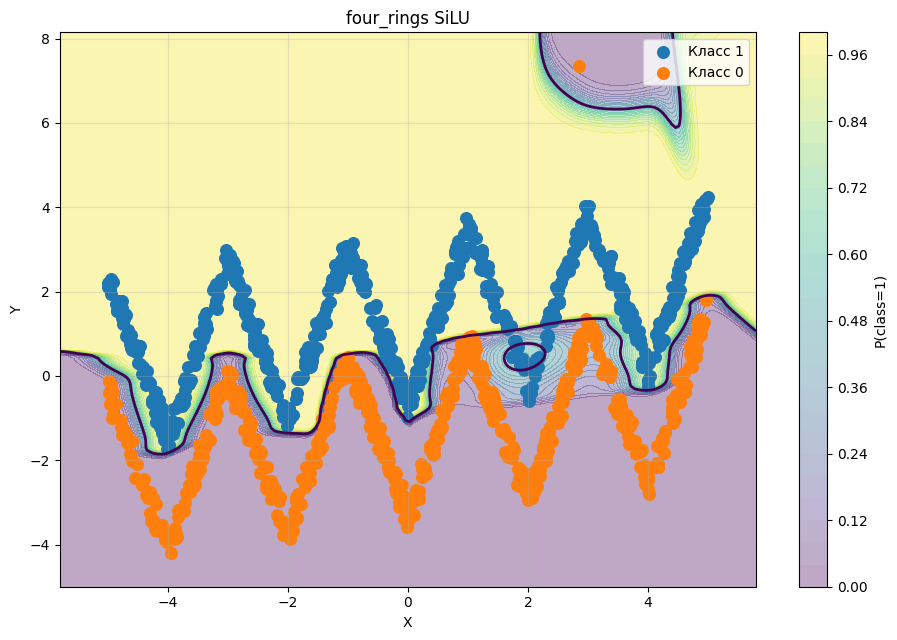

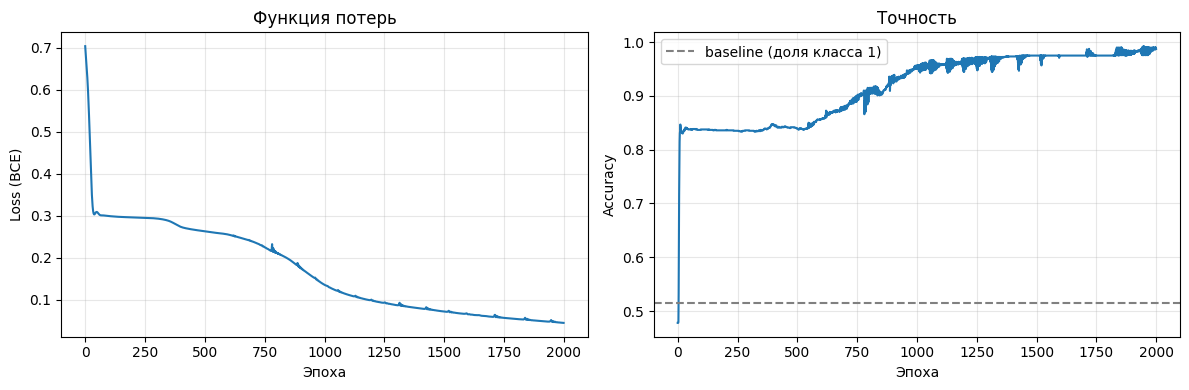

Итог: loss = 0.0453, accuracy = 0.988


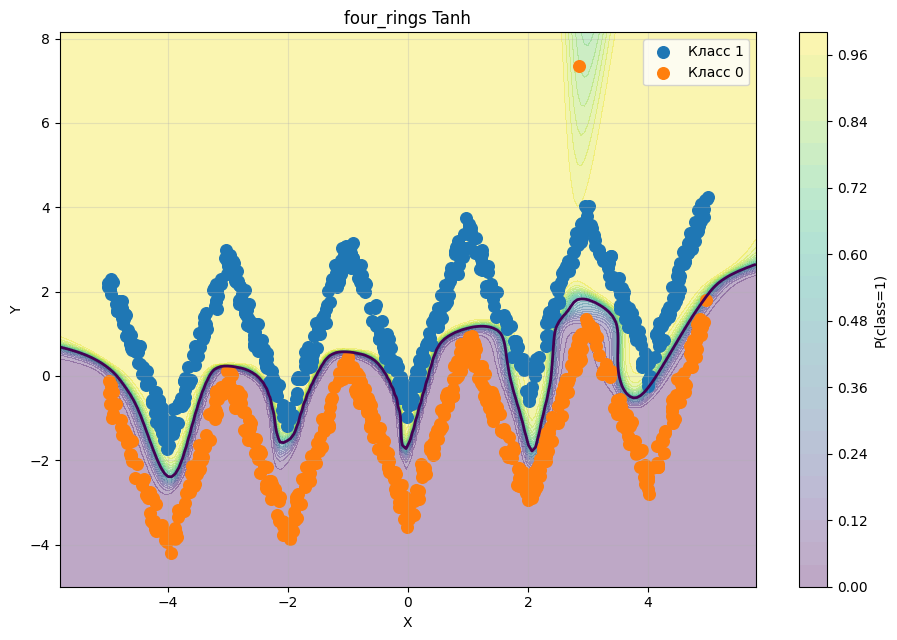

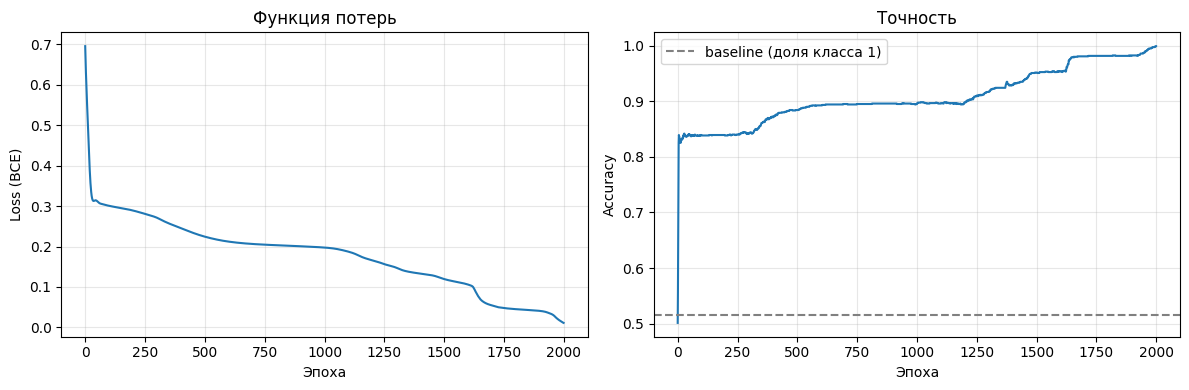

Итог: loss = 0.0112, accuracy = 0.999


In [23]:
# Напиши код здесь
results = {}
for func in [nn.ReLU, nn.SiLU, nn.Tanh]:
    history = run_experiment(
        make_model(func, h=10, depth=2),
        zigzag_gap1X,
        zigzag_gap1Y,
        normalize=True,
        title=f"four_rings {func.__name__}",
    )
    results[func.__name__] = history[-1]

In [24]:
pd.DataFrame(results, index=["loss", "acc"]).T

,loss,acc
ReLU,0.105497,0.951707
SiLU,0.045306,0.987510
Tanh,0.011187,0.999167


мне тут SiLU больше нравится, но ReLU дает композицию линейных функций, которой не хватило нейронов, так что буду использовать ее

In [25]:
results = {}
for h in [4, 8, 10, 14]:
    history = run_experiment(
        make_model(nn.ReLU, h=h, depth=2),
        zigzag_gap1X,
        zigzag_gap1Y,
        normalize=True,
        title=f"four_rings h={h}",
        plot=False,
        do_print_history=False,
    )
    results[h] = history[-1]
pd.DataFrame(results, index=["loss", "acc"]).T

,loss,acc
4,0.280465,0.843464
8,0.169188,0.905912
10,0.105497,0.951707
14,0.154743,0.903414


результат отличается от результата в эксперименте 2 в задании 4, больше нейронов на слой не означает лучше качество. может тут ReLU не хватает слоев?

In [26]:
results = {}
for depth in [1, 3, 5, 10, 15, 30]:
    history = run_experiment(
        make_model(nn.ReLU, h=10, depth=depth),
        zigzag_gap1X,
        zigzag_gap1Y,
        normalize=True,
        title=f"four_rings depth={depth}",
        plot=False,
        do_print_history=False,
    )
    results[depth] = history[-1]
pd.DataFrame(results, index=["loss", "acc"]).T

,loss,acc
1,0.207031,0.890924
3,0.058755,0.975853
5,0.260370,0.871774
10,0.096807,0.942548
15,0.692173,0.522065
30,0.692173,0.522065


In [27]:
print("baseline", four_ringsY.mean())

baseline 0.4993758


Опять же, я вижу, что большое количество слоев не гарантирует качество: на 5 слоях модель достигала наилучшего качества, при том что на 30 слоях она угадывала незначительно лучше бейзлайна (0.5 ~ 0.499)

Ячейка ниже присутствовала в ноутбуке со старта, ее писал не я, похоже забыли подчистить)

**Результаты эксперимента 3**

- $Relu$ показала себя очень хорошо, и неудивительно: ведь граница представляется в виде композиции линейных функций.
- Гладкие функции активации тоже показывают хорошие результаты, но нужно больше итераций и нейронов.

---

## Задание 6 [1,5 балла]

Проверь, как хорошо обучается на датасете `dataset_zigzag_gap1.csv` глубокая нейросеть с $\mathrm{SiLU}$.
1.   Сделай выводы **[1 балл]**.
2.   Просмотри все результаты экспериментов ещё раз и подведи итоги **[0,5 балла]**.


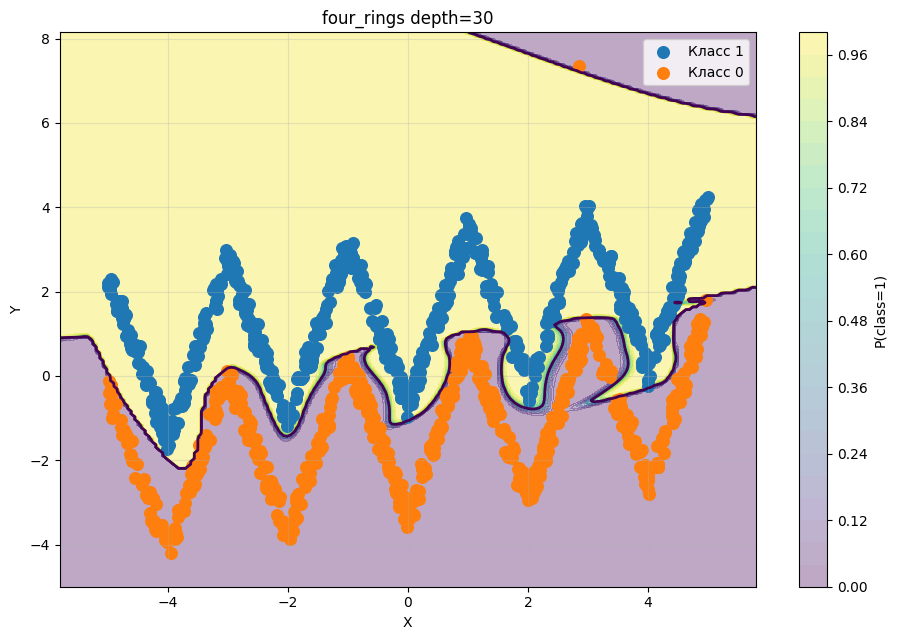

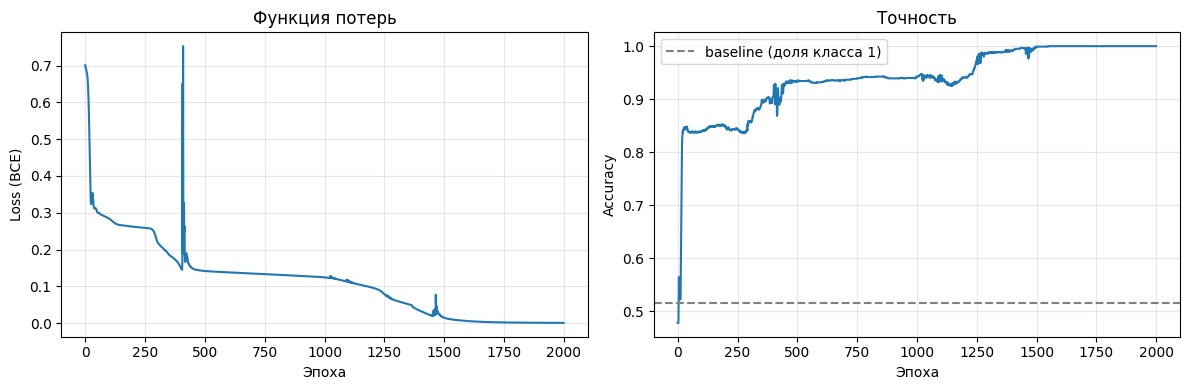

Итог: loss = 0.0010, accuracy = 1.000


In [28]:
# Напиши код здесь
# Наилучшая модель из экспериментов 5 задания, судя по всему
_ = run_experiment(
    make_model(nn.SiLU, h=10, depth=5),
    zigzag_gap1X,
    zigzag_gap1Y,
    normalize=True,
    title=f"four_rings depth={depth}",
)

как будто бы получился максимально переобученный слоп :(


не знаю какие выводы надо сделать на часах 3:22 но чето попробую сформулировать

маленькая ошибка не всегда плохо: сразу выше мы видим абсолютно бесполезную модель с нулевой функцией потерь и абсолютной точностью (надо тестовую выборку еще иметь)
ReLU выдает жесткие колена, в то время как SiLU чуть более мягкие и она мне больше нравится пока что (хз как потом они будут применяться)
ну и все выводы до этого шире слои чаще всего хорошо, больше слоев не всегда хорошо (мб мало эпох просто было на много слоев??)